# Comparisons and illustrative stock aggregation

Compare energy, intensity and coincident profiles using explicit demonstration weights.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW, EnergyPlus 24.2.

## Understanding the API in this lesson

A building EUI and an aggregate stock EUI use different weighting logic. With count weights `wᵢ`, aggregate EUI is `Σ(wᵢ Eᵢ) / Σ(wᵢ Aᵢ)`, where energy is in kWh and conditioned area in m². It is not generally the simple mean of building EUIs.

The example weights are illustrative counts, not Swedish stock data. The workflow figure's compare stage is performed here with pandas using core results. EPSM supplies building-level simulation evidence; the caller remains responsible for the validity of the population weights and aggregation question.

Reference: [From observed geometry to an accepted energy comparison](../../docs/figures/workflow.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


### Stock EUI requires weighted energy and area

The diagram shows accounting dependencies, not a conversion from EUI into hourly demand. The calculation below uses actual accepted building results with illustrative counts. Averaging individual EUIs with count weights alone is generally wrong; area must also enter the weights. These example counts are not nationally representative expansion factors.

The following original diagram is conceptual API guidance; the later charts and tables report the computed example values.

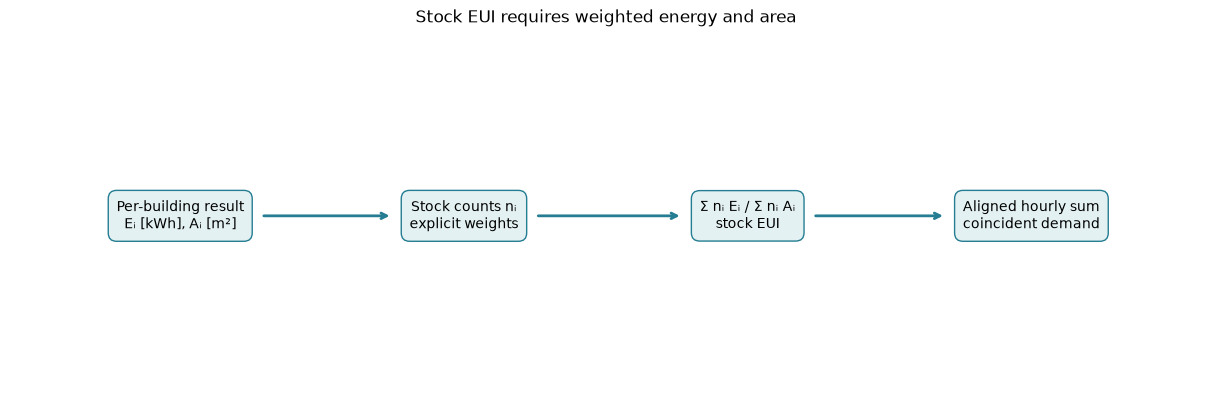

In [2]:
from demo.support.common import flow
flow(['Per-building result\nEᵢ [kWh], Aᵢ [m²]', 'Stock counts nᵢ\nexplicit weights', 'Σ nᵢ Eᵢ / Σ nᵢ Aᵢ\nstock EUI', 'Aligned hourly sum\ncoincident demand'], 'Stock EUI requires weighted energy and area', figsize=(12, 4))

## Run two contrasting sizes

Area normalization and population weighting answer different questions. Both buildings use the same climate and construction to isolate size and exposure.

### Read the code and output

The two sizes share other inputs, making floor area and exposure the intended contrast. Read absolute kWh alongside EUI: a larger building can consume more total energy and less per square metre. These are complementary findings rather than a contradiction.

Reference: [Retained example: context sensitivity across three climates](../../docs/figures/context-sensitivity.svg). This linked documentation illustration is separate from the outputs computed below.

,case,area_m2,heating_kwh,eui
0,small,100.0,7348.044143,73.480441
1,large,2400.0,89122.379307,37.134325


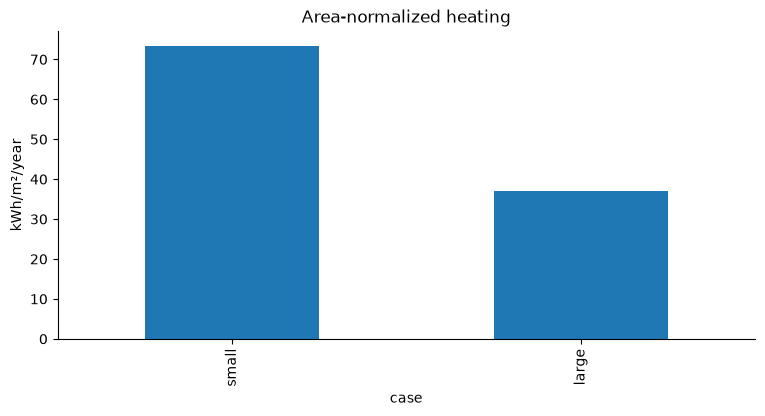

In [3]:
base=building(); specs={"small":base.updated(geometry=geometry(Footprint.rectangle(10,10),storeys=1)),"large":base.updated(geometry=geometry(Footprint.rectangle(30,20),storeys=4))}
results={name:EnergyPlusRunner(engine()).run(b,OUT/name) for name,b in specs.items()}
rows=[{"case":name,"area_m2":specs[name].geometry.conditioned_floor_area_m2,"heating_kwh":r.scalars["space_heating_demand_kwh"],"eui":r.scalars["space_heating_demand_eui_kwh_m2"]} for name,r in results.items()]
frame=table(rows).set_index("case")
fig, ax = plt.subplots(figsize=(9, 4))
frame.eui.plot.bar(ax=ax, ylabel="kWh/m²/year",title="Area-normalized heating"); plt.show(); plt.close(fig)

## Aggregate with explicit illustrative counts

These weights are teaching values, not Swedish building counts. A weighted stock EUI divides total weighted energy by total weighted floor area, rather than averaging building EUIs.

### Read the code and output

The alternative weighted-average assertion uses weights proportional to count times area, which reproduces the ratio of totals. Replacing those with counts alone would average building intensities differently. Always state whether a weight represents buildings, floor area, sample expansion or another quantity.

,field,value
0,weighted_energy_kwh,251725.20004189824
1,weighted_area_m2,5800.0
2,weighted_EUI_kwh_m2,43.40089655894797


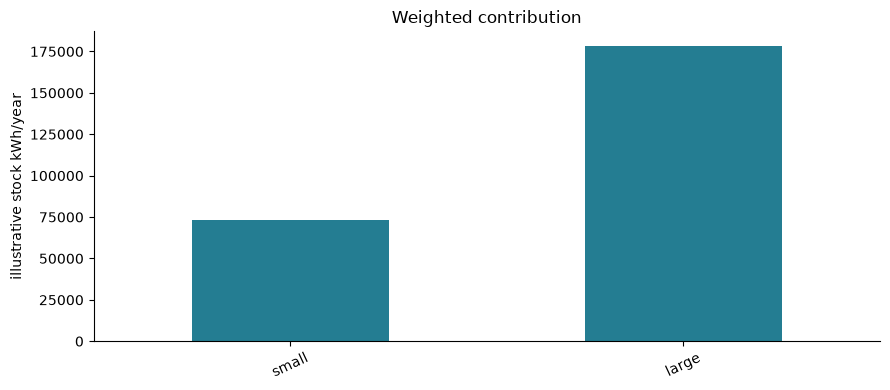

In [4]:
weights=pd.Series({"small":10,"large":2},name="illustrative_count")
energy=(frame.heating_kwh*weights).sum(); area=(frame.area_m2*weights).sum()
stock_eui=energy/area
assert np.isclose(stock_eui,np.average(frame.eui,weights=frame.area_m2*weights))
table({"weighted_energy_kwh":energy,"weighted_area_m2":area,"weighted_EUI_kwh_m2":stock_eui})
bars((frame.heating_kwh*weights).to_dict(),"illustrative stock kWh/year","Weighted contribution")

## Align profiles before calculating peaks

Use the validated time axis and reject mismatches. Summing individual peaks overstates a coincident peak unless they occur together.

### Read the code and output

Matching time axes is necessary before summing weighted hourly profiles. Missing values would indicate an alignment problem rather than zero demand. The coincident-peak inequality is a useful consistency check but does not provide measured simultaneity or a network sizing margin.

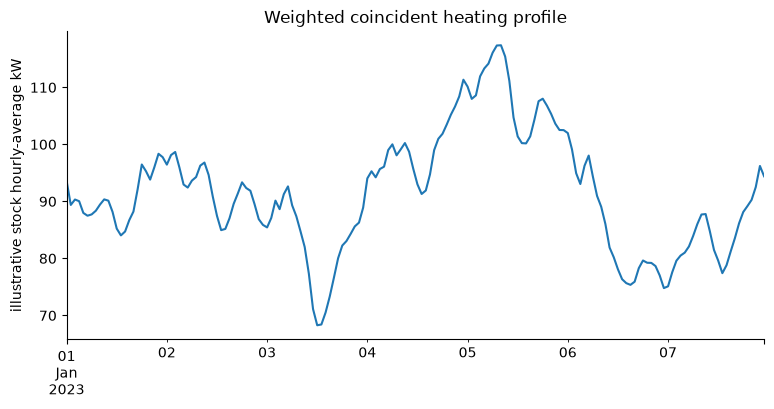

In [5]:
profiles=pd.DataFrame({name:result_frame(r).space_heating_demand_kwh for name,r in results.items()})
assert not profiles.isna().any().any()
total=profiles.mul(weights).sum(axis=1)
assert total.max()<=float((profiles.max()*weights).sum())+1e-6
fig, ax = plt.subplots(figsize=(9, 4))
total.iloc[:168].plot(ax=ax, ylabel="illustrative stock hourly-average kW",title="Weighted coincident heating profile"); plt.show(); plt.close(fig)

## Interpretation and next experiment

National estimates require justified counts and representativeness. The aggregation mathematics is useful here; the demonstration weights carry no national inference.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.